# Mouse breathing sensors: first look at one session

**Session:** 2026-06-18_16-25-09_000

**Goal:** three sensors record breathing simultaneously (thermistor, airflow, LFP in the olfactory epithelium). Each fails in different situations. The long-term aim is to combine them into one robust breathing signal. This notebook checks whether that is feasible in this session: do the sensors share the breathing rhythm, and when do they disagree?

Questions for discussion are collected at the end.


**Big Picture Results**
1. All three sensors track the same breathing rhythm. In the clean stretches all three cycle together with consistent timing while each sensor has its strengths and weaknesses. 

- Thermistor: cleanest rhythm but is slow and misses fast events.
- Airflow: most direct and fast but noisiest as well. 
- LFP: clear rhythm but contains extra fast activity, sign also depends on the channel. 
No single sensor trumps the others so a combination should help accuracy. 

2. Disagreement is episodic and not constant

    The sensors are consistent majority of the time (details in sec 7) and break down during brief events: muscle activity or breathing halts. Our method would have to distinguish between one sensor failing and from breathing actually stopping. 

3. Phase has main weakness

    Phase helps us compare the different signals but fast non-breathing activity produce extra cycles. The filter band is the most important parameter in this case since it determines how many cycles get through. 
    A narrower filter band can remove extra cycles but it would also remove faster breathing cycles. 

All this is just the results from one session, the next step would be to try and establish a pattern in more data sets. 

## 1. Setup
Loads the data and defines helper functions used throughout.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA = ROOT / "data" / "M1" / "2026-06-18_16-25-09_000" / "alf"
FS = 1000                                   # samples per second
plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"Thermistor": "#2a78d6", "Airflow": "#eb6834", "LFP": "#1baf7a"}

# ---- data ----
thermistor = np.load(DATA / "_cavelli_thermistor.signal.npy").astype(float)
airflow    = np.load(DATA / "_cavelli_airflow.signal.npy").astype(float)
chest      = np.load(DATA / "_cavelli_chest.signal.npy").astype(float)
lfp_all    = np.load(DATA / "_cavelli_lfp.signal.npy").astype(float)     # (samples, 10 channels)
emg        = np.load(DATA / "_cavelli_emg.signal.npy").astype(float)[:, 0]
cam_times  = np.load(DATA / "leftCamera.times.npy")
lfp = lfp_all[:, 0]                                                       # channel choice: section 9
t = np.arange(len(thermistor)) / FS
sensors = {"Thermistor": thermistor, "Airflow": airflow, "LFP": lfp}

# ---- helpers ----
zscore = lambda x: (x - x.mean()) / x.std()

def bandpass(x, lo, hi, order=3):
    b, a = signal.butter(order, [lo, hi], btype="band", fs=FS)
    return signal.filtfilt(b, a, x, axis=0)          # forward-backward: no time shift

def get_phase(x, lo=1, hi=15):
    return np.angle(signal.hilbert(bandpass(x, lo, hi), axis=0))

def sliding_plv(p1, p2, win_s=5, step_s=1):
    # phase-locking value in sliding windows; returns window CENTER times and values
    W, S = int(win_s * FS), int(step_s * FS)
    starts = np.arange(0, len(p1) - W, S)
    vals = np.array([np.abs(np.mean(np.exp(1j * (p1[s:s+W] - p2[s:s+W])))) for s in starts])
    return (starts + W / 2) / FS, vals

def smooth(x, win_s):
    W = int(win_s * FS)
    return np.convolve(x, np.ones(W) / W, mode="same")

def plot_window(data, start, length=10, title=""):
    i0, i1 = int(start * FS), int((start + length) * FS)
    plt.figure()
    for k, (name, x) in enumerate(data.items()):
        plt.plot(t[i0:i1], zscore(x)[i0:i1] - 5 * k, color=COLORS[name], lw=1, label=name)
    plt.yticks([]); plt.xlabel("time (s)"); plt.title(title, loc="left")
    plt.legend(loc="upper right", ncol=3); plt.show()

CLEAN, MESSY = 295, 90      # example windows (start times, s); see section 4

## 2. Data check
All physiological signals share one clock at 1000 Hz; camera frames are timestamped on the same clock.

In [2]:
n = int(np.load(DATA / "ephys.nSamples.npy"))
print(f"Recording: {n} samples at {FS} Hz = {n / FS:.1f} s")
for name, x in {"thermistor": thermistor, "airflow": airflow, "chest": chest,
                "LFP (10 ch)": lfp_all, "EMG": emg}.items():
    print(f"  {name:12s} {len(x)} samples  {'OK' if len(x) == n else 'MISMATCH'}")
print("Chest sensor non-zero samples:", np.count_nonzero(chest), "-> not recorded in this session")

gaps = np.diff(cam_times)
print(f"Video: {len(cam_times)} frames, {cam_times[0]:.1f}-{cam_times[-1]:.1f} s, "
      f"{1 / np.median(gaps):.1f} fps, largest gap {gaps.max() * 1000:.1f} ms")

Recording: 397714 samples at 1000 Hz = 397.7 s
  thermistor   397714 samples  OK
  airflow      397714 samples  OK
  chest        397714 samples  OK
  LFP (10 ch)  397714 samples  OK
  EMG          397714 samples  OK
Chest sensor non-zero samples: 0 -> not recorded in this session
Video: 22217 frames, 17.7-388.0 s, 60.0 fps, largest gap 16.7 ms


**Result:** all signals have the same length, so samples line up across sensors. The video runs at a steady 60 fps with no dropped frames and covers 17.7–388 s. The chest sensor is empty in this session.

## 3. Whole session
Too compressed to see individual breaths, but useful for locating events. EMG (muscle activity) is shown as a proxy for movement. Shaded: the clean (gold) and messy (gray) example windows.

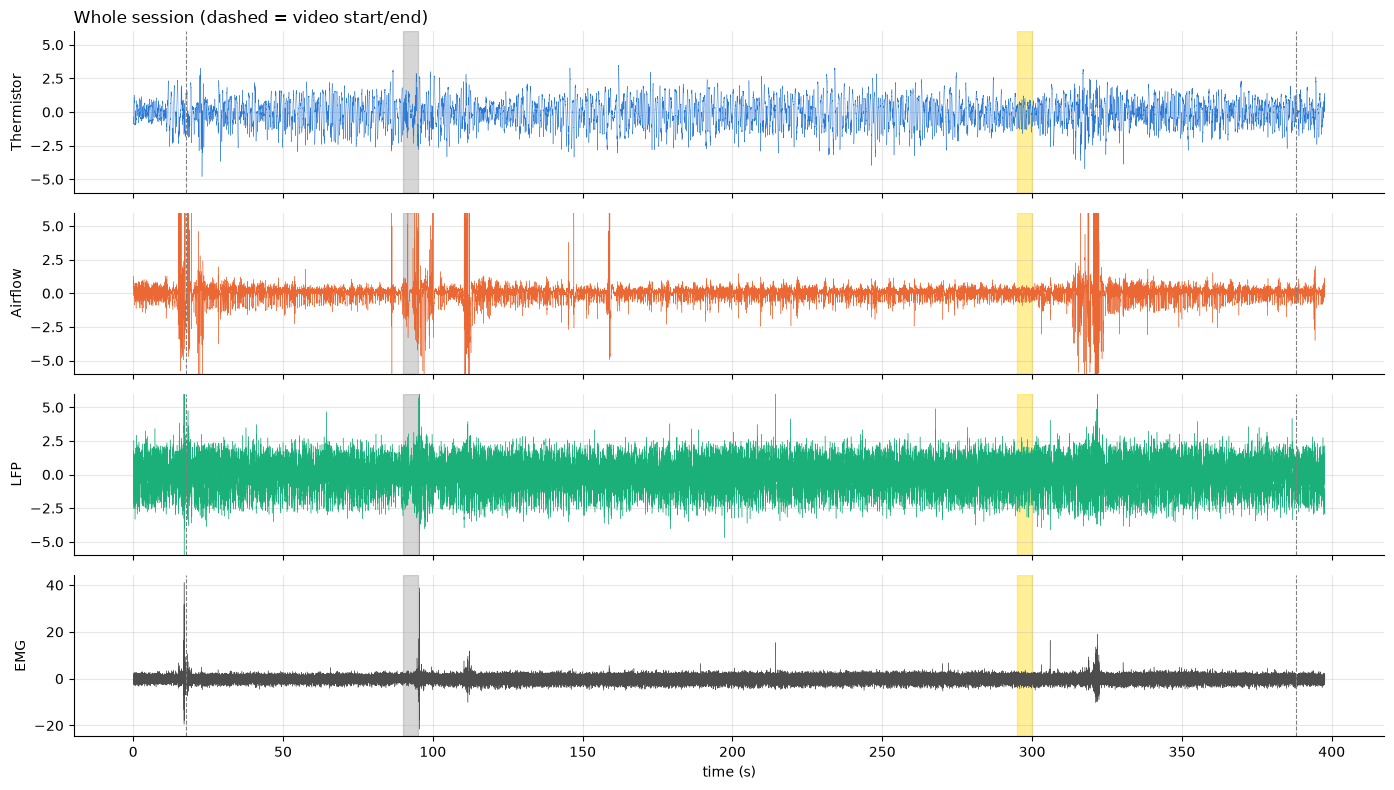

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(14, 8), sharex=True)
for ax, (name, x) in zip(axes, sensors.items()):
    ax.plot(t, zscore(x), color=COLORS[name], lw=0.3)
    ax.set_ylabel(name); ax.set_ylim(-6, 6)          # clip large spikes
axes[3].plot(t, zscore(emg), color="0.3", lw=0.3); axes[3].set_ylabel("EMG")
axes[3].set_xlabel("time (s)")
for ax in axes:
    ax.axvline(cam_times[0], color="gray", ls="--", lw=0.8)
    ax.axvline(cam_times[-1], color="gray", ls="--", lw=0.8)
    ax.axvspan(CLEAN, CLEAN + 5, color="gold", alpha=0.4)
    ax.axvspan(MESSY, MESSY + 5, color="0.6", alpha=0.4)
axes[0].set_title("Whole session (dashed = video start/end)", loc="left")
plt.tight_layout(); plt.show()

**Result:** large airflow and LFP events coincide with EMG bursts (around 18, 95 and 320 s). Most of the session is quiet.

## 4. What the signals look like
Two 10-s examples. The clean window is where all three sensor pairs agree best (scored over every 5-s window by the weakest pair); the messy window is a low-agreement stretch. These are extremes, not typical; the typical case is in section 7.

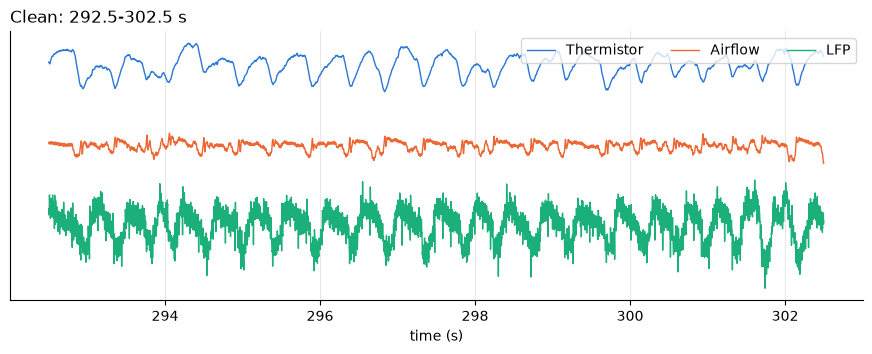

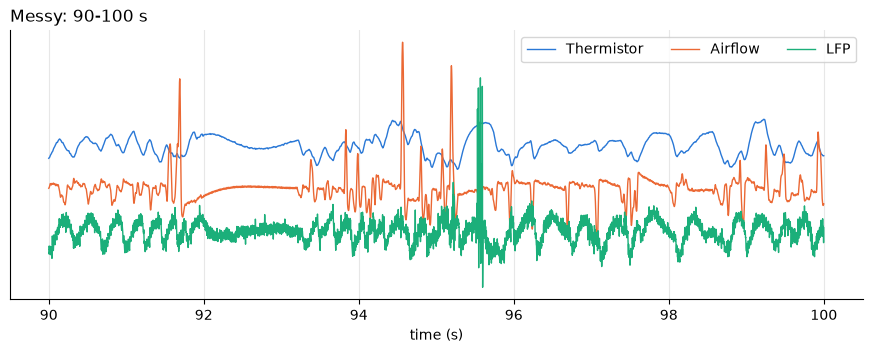

In [4]:
plot_window(sensors, CLEAN - 2.5, title=f"Clean: {CLEAN - 2.5:.1f}-{CLEAN + 7.5:.1f} s")
plot_window(sensors, MESSY,       title=f"Messy: {MESSY}-{MESSY + 10} s")

**Result:** in the clean window all three sensors show one cycle per breath. The thermistor is smooth, the airflow has sharp dips, and the LFP carries the breathing rhythm under faster activity. In the messy window the signals flatten around 92–93 s and the LFP shows an artifact burst around 95.5 s.

## 5. Frequency content

Welch power spectra over the whole session, each normalized to its own peak.

Thermistor peak at 1.22 Hz
Airflow    peak at 7.32 Hz
LFP        peak at 2.32 Hz


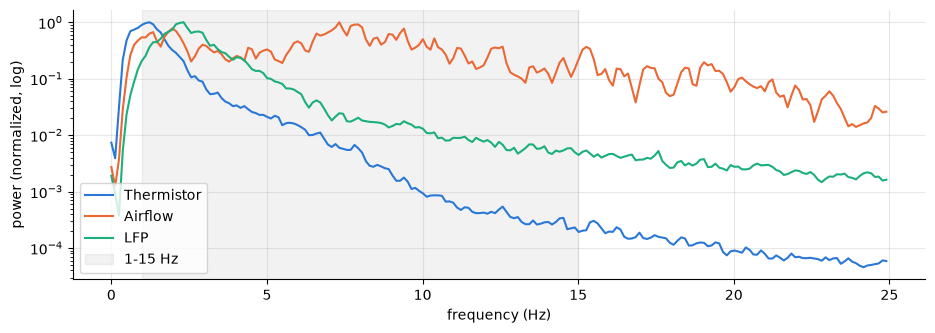

In [5]:
plt.figure()
for name, x in sensors.items():
    f, p = signal.welch(x, FS, nperseg=8192)
    keep = f < 25
    plt.semilogy(f[keep], p[keep] / p[keep].max(), color=COLORS[name], label=name)
    print(f"{name:10s} peak at {f[keep][np.argmax(p[keep])]:.2f} Hz")
plt.axvspan(1, 15, color="gray", alpha=0.1, label="1-15 Hz")
plt.xlabel("frequency (Hz)"); plt.ylabel("power (normalized, log)"); plt.legend(); plt.show()

**Result:** At first glance, each signal peaks at a slightly different frequency: 
 - thermistor: 1.2Hz
 - LFP: 2.3Hz
 - Airflow: 7.3Hz
 disagreeing about how fast the mouse is breathing. (Keep in mind that the signals are also broad humps and not single spikes so peaks only reveal that much.) 
 Two possibilities:

  - each signal favors different changes
  - sensors are recording noise

How to decide?

We use a coherence plot 

Thermistor - Airflow : mean coherence  1-3 Hz 0.24 | 3-6 Hz 0.19 | 6-15 Hz 0.12 | highest at 2.69 Hz | chance (1-15 Hz) 0.01
Thermistor - LFP     : mean coherence  1-3 Hz 0.63 | 3-6 Hz 0.55 | 6-15 Hz 0.08 | highest at 1.46 Hz | chance (1-15 Hz) 0.00
Airflow    - LFP     : mean coherence  1-3 Hz 0.14 | 3-6 Hz 0.09 | 6-15 Hz 0.10 | highest at 1.46 Hz | chance (1-15 Hz) 0.01


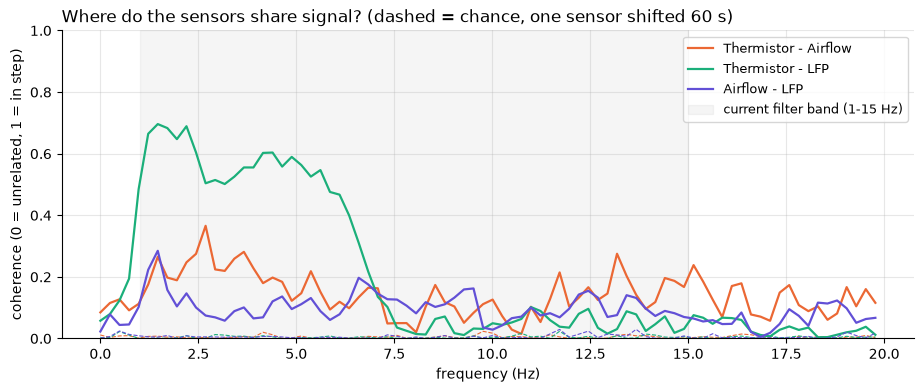

In [18]:
# ---- 5b. Coherence: where do the sensors share signal? ----
coh_pairs = [("Thermistor", "Airflow"), ("Thermistor", "LFP"), ("Airflow", "LFP")]
coh_colors = ["#eb6834", "#1baf7a", "#6250d6"]
SHIFT = 60 * FS                       # chance level: same pair with one sensor shifted 60 s
NPERSEG = 4096                        # ~4-s chunks -> 0.24 Hz resolution, ~190 chunks

plt.figure(figsize=(11, 4))
for (a, b), c in zip(coh_pairs, coh_colors):
    f, C = signal.coherence(sensors[a], sensors[b], FS, nperseg=NPERSEG)
    _, C0 = signal.coherence(sensors[a], np.roll(sensors[b], SHIFT), FS, nperseg=NPERSEG)
    k = f <= 20
    plt.plot(f[k], C[k], color=c, lw=1.6, label=f"{a} - {b}")
    plt.plot(f[k], C0[k], color=c, lw=0.8, ls="--")
    band = lambda lo, hi: C[(f >= lo) & (f < hi)].mean()
    pk = f[(f >= 0.5) & (f <= 15)][np.argmax(C[(f >= 0.5) & (f <= 15)])]
    print(f"{a:10s} - {b:8s}: mean coherence  1-3 Hz {band(1, 3):.2f} | 3-6 Hz {band(3, 6):.2f} | "
          f"6-15 Hz {band(6, 15):.2f} | highest at {pk:.2f} Hz | chance (1-15 Hz) {C0[(f >= 1) & (f < 15)].mean():.2f}")
plt.axvspan(1, 15, color="gray", alpha=0.08, label="current filter band (1-15 Hz)")
plt.ylim(0, 1); plt.xlabel("frequency (Hz)"); plt.ylabel("coherence (0 = unrelated, 1 = in step)")
plt.title("Where do the sensors share signal? (dashed = chance, one sensor shifted 60 s)", loc="left")
plt.legend(loc="upper right", fontsize=9); plt.show()

## 6. Breathing phase
Each signal is band-passed (1–15 Hz) and converted to phase with the Hilbert transform. Phase gives the position within each cycle (−π to π), which makes sensors with different units comparable.

How to read the plots below:
- Each ramp from −π to π is one cycle; the title gives the cycle count.
- Dotted lines mark the start of each thermistor cycle, as a reference in every panel.
- Bottom panel: thermistor phase minus each other sensor's phase. **Flat = in step** (its height is the lag); jumps = out of step.

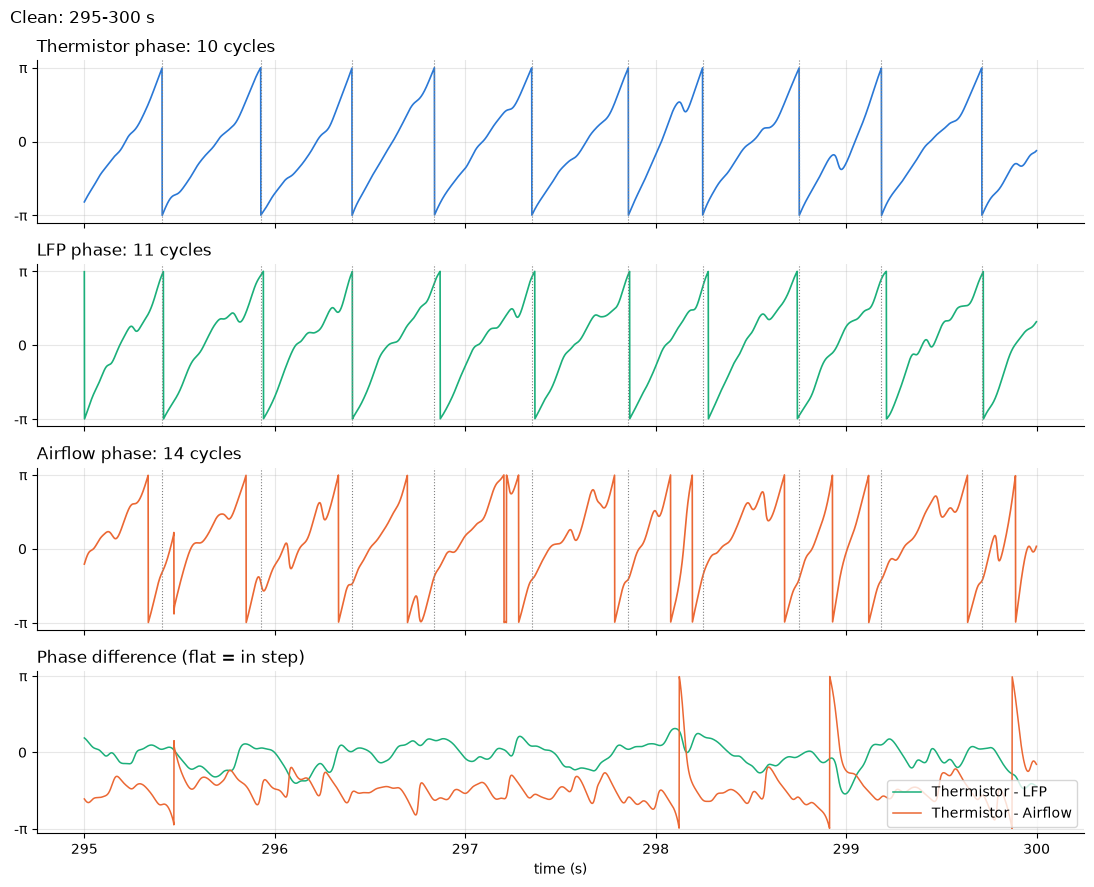

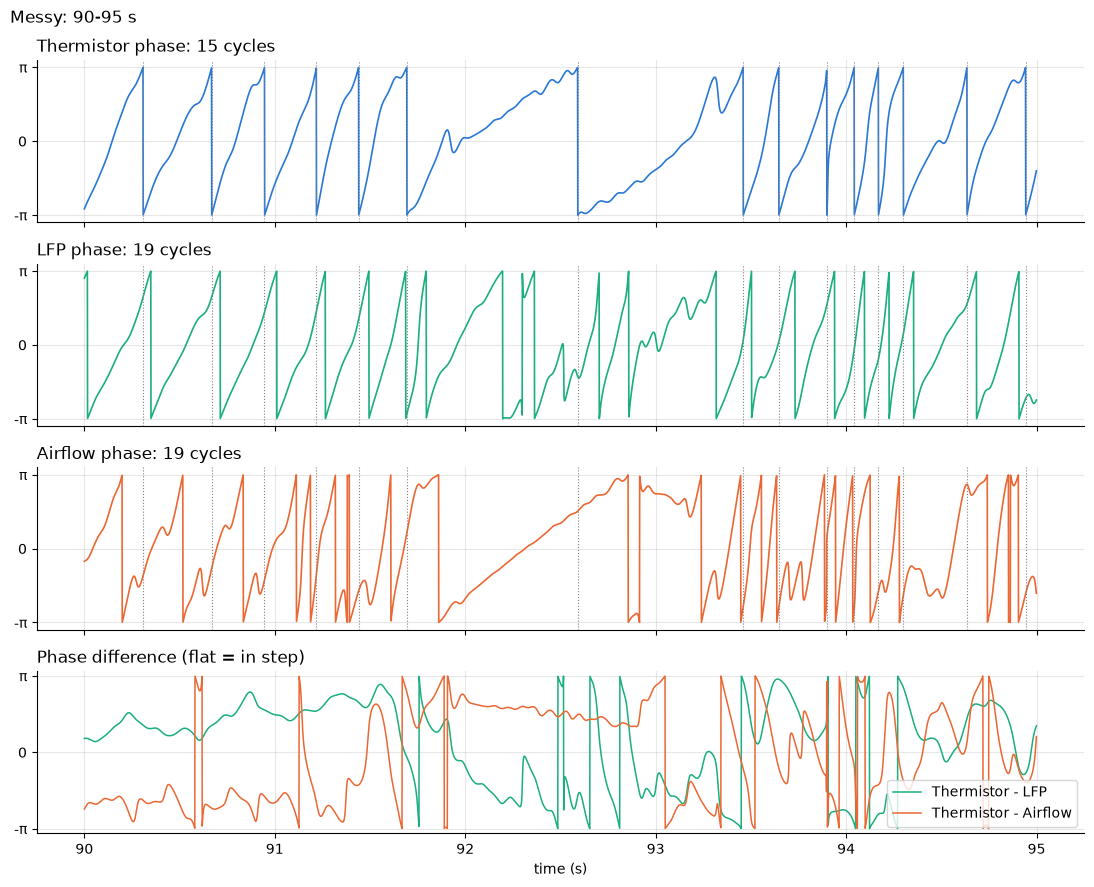

In [19]:
phase = {name: get_phase(x) for name, x in sensors.items()}

def compare_phases(start, length=5, title=""):
    i0, i1 = int(start * FS), int((start + length) * FS)
    tt = t[i0:i1]
    th_starts = np.where(np.diff(phase["Thermistor"][i0:i1]) < -np.pi)[0]   # thermistor wraps

    fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
    for ax, name in zip(axes[:3], ["Thermistor", "LFP", "Airflow"]):
        p = phase[name][i0:i1]
        n_cycles = round((np.unwrap(p)[-1] - np.unwrap(p)[0]) / (2 * np.pi))
        ax.plot(tt, p, color=COLORS[name], lw=1.2)
        ax.set_title(f"{name} phase: {n_cycles} cycles", loc="left")
        ax.set_yticks([-np.pi, 0, np.pi]); ax.set_yticklabels(["-π", "0", "π"])
        for i in th_starts:
            ax.axvline(tt[i], color="gray", ls=":", lw=0.8)
    for name in ["LFP", "Airflow"]:
        diff = np.angle(np.exp(1j * (phase["Thermistor"][i0:i1] - phase[name][i0:i1])))
        axes[3].plot(tt, diff, color=COLORS[name], lw=1.1, label=f"Thermistor - {name}")
    axes[3].set_ylim(-np.pi - 0.2, np.pi + 0.2)
    axes[3].set_yticks([-np.pi, 0, np.pi]); axes[3].set_yticklabels(["-π", "0", "π"])
    axes[3].set_title("Phase difference (flat = in step)", loc="left")
    axes[3].legend(loc="lower right"); axes[3].set_xlabel("time (s)")
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    plt.tight_layout(); plt.show()

compare_phases(CLEAN, title=f"Clean: {CLEAN}-{CLEAN + 5} s")
compare_phases(MESSY, title=f"Messy: {MESSY}-{MESSY + 5} s")

**Result:**
- **Clean:** thermistor and LFP restart nearly on the same lines (difference near 0). The airflow leads the thermistor by a steady fraction of a cycle, with occasional extra cycles (the brief spikes in the difference line).
- **Messy:** the difference lines jump around. Long, slow ramps around 92–93 s are not slow breaths: the signals are nearly flat there and phase is undefined.
- The LFP and airflow show more cycles than the thermistor because their fast activity produces extra short cycles.

## 7. Agreement over the whole session
Phase-locking value (PLV) in 5-s windows (~10 breaths): 1 = constant phase relationship, 0 = none. EMG below, smoothed over the same 5 s.

Thermistor - Airflow : median PLV 0.72, 60% of windows above 0.7
Thermistor - LFP     : median PLV 0.62, 23% of windows above 0.7
Airflow    - LFP     : median PLV 0.38, 0% of windows above 0.7


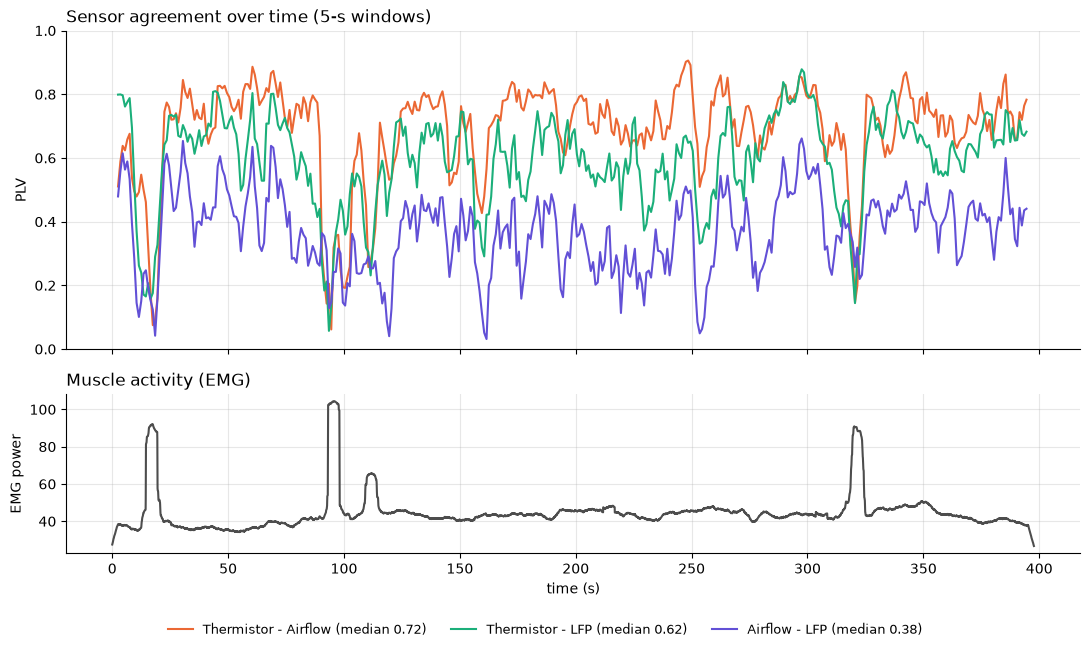

Thermistor - Airflow : lag -1.48 rad (-85°, -0.24 cycle)
Thermistor - LFP     : lag -0.37 rad (-21°, -0.06 cycle)
Airflow    - LFP     : lag +1.12 rad (+64°, +0.18 cycle)


In [25]:
pairs = [("Thermistor", "Airflow"), ("Thermistor", "LFP"), ("Airflow", "LFP")]
pair_colors = [COLORS["Airflow"], COLORS["LFP"], "#6250d6"]
emg_power = np.sqrt(smooth(bandpass(emg, 30, 300) ** 2, 5))

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for (a, b), c in zip(pairs, pair_colors):
    centers, vals = sliding_plv(phase[a], phase[b])
    axes[0].plot(centers, vals, color=c, label=f"{a} - {b} (median {np.median(vals):.2f})")
    print(f"{a:10s} - {b:8s}: median PLV {np.median(vals):.2f}, "
          f"{np.mean(vals > 0.7) * 100:.0f}% of windows above 0.7")
axes[0].set_ylim(0, 1); axes[0].set_ylabel("PLV")
axes[0].set_title("Sensor agreement over time (5-s windows)", loc="left")
axes[1].plot(t[::50], emg_power[::50], color="0.3")
axes[1].set_ylabel("EMG power"); axes[1].set_xlabel("time (s)")
axes[1].set_title("Muscle activity (EMG)", loc="left")

# legend below the whole figure, so it doesn't cover any data
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=9, frameon=False)
plt.tight_layout(rect=[0, 0.05, 1, 1])      # leave room at the bottom for the legend
plt.show()

# Typical phase lag between each pair over the whole session (circular mean of the phase difference)
for a, b in pairs:
    m = np.mean(np.exp(1j * (phase[a] - phase[b])))
    lag = np.angle(m)
    print(f"{a:10s} - {b:8s}: lag {lag:+.2f} rad ({np.degrees(lag):+.0f}°, {lag / (2*np.pi):+.2f} cycle)")

**Result:** the two direct breathing sensors (thermistor, airflow) agree strongly most of the time; agreement with LFP is moderate; and agreement is weakest between the two noisiest sensors (airflow, LFP). The largest drops occur near EMG bursts. Not every drop is muscle-related. The thermistor is about 20 deg behind the LFP (neg). 

## 8. A possible breathing pause (85–100 s)
The EMG above is smoothed over 5 s, which spreads short bursts out. Here: EMG at 0.25-s resolution, and the strength (Hilbert amplitude) of each breathing signal relative to its typical level.

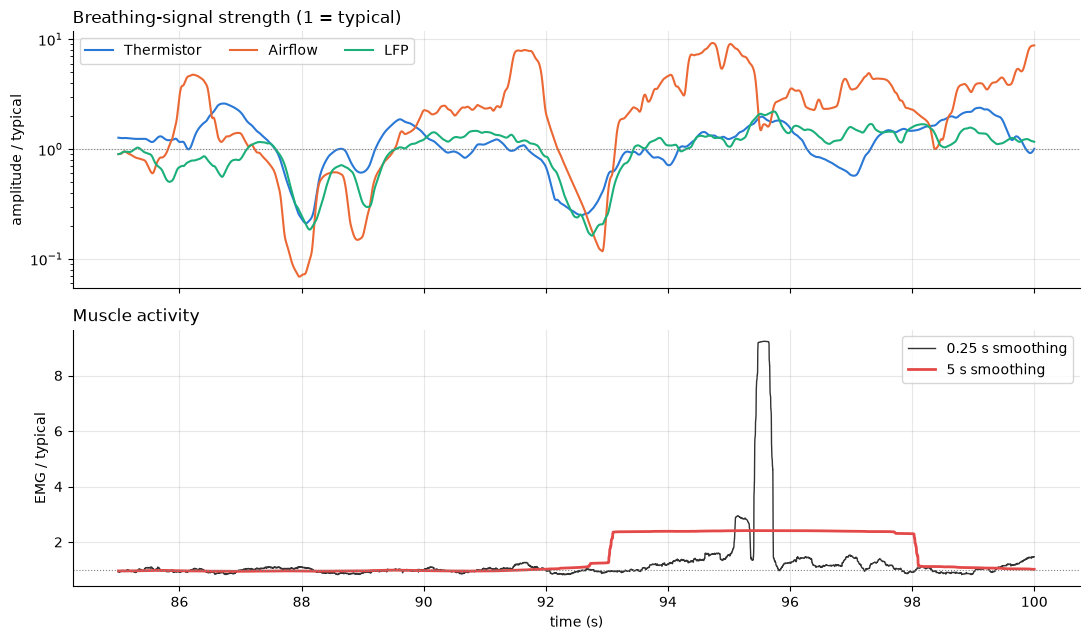

In [26]:
emg_hf     = bandpass(emg, 30, 300)
emg_fine   = np.sqrt(smooth(emg_hf ** 2, 0.25))
emg_coarse = np.sqrt(smooth(emg_hf ** 2, 5))
amp = {name: smooth(np.abs(signal.hilbert(bandpass(x, 1, 15))), 0.5) for name, x in sensors.items()}

i0, i1 = 85 * FS, 100 * FS
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for name, a_ in amp.items():
    axes[0].plot(t[i0:i1], a_[i0:i1] / np.median(a_), color=COLORS[name], label=name)
axes[0].axhline(1, color="0.5", lw=0.8, ls=":")
axes[0].set_yscale("log"); axes[0].set_ylabel("amplitude / typical")
axes[0].set_title("Breathing-signal strength (1 = typical)", loc="left"); axes[0].legend(ncol=3)
axes[1].plot(t[i0:i1], emg_fine[i0:i1] / np.median(emg_fine), color="0.2", lw=1, label="0.25 s smoothing")
axes[1].plot(t[i0:i1], emg_coarse[i0:i1] / np.median(emg_coarse), color="#e34948", lw=2, label="5 s smoothing")
axes[1].axhline(1, color="0.5", lw=0.8, ls=":")
axes[1].set_ylabel("EMG / typical"); axes[1].set_xlabel("time (s)"); axes[1].legend()
axes[1].set_title("Muscle activity", loc="left")
plt.tight_layout(); plt.show()

**Result:** around 92.5–93 s (and ~88 s), all three breathing signals drop to roughly a quarter of their typical strength **at the same time**, while the EMG stays at its typical level. Three independent sensors going quiet together suggests a real pause in breathing rather than sensor failure. The sharp EMG burst at ~95.5 s coincides with the LFP artifact burst. 

An explanation for this could be the mouse swallowing as mice pause breathing when they swallow. (check this against video)

## 9. LFP channel choice
Median agreement of each LFP channel with the two direct breathing sensors.

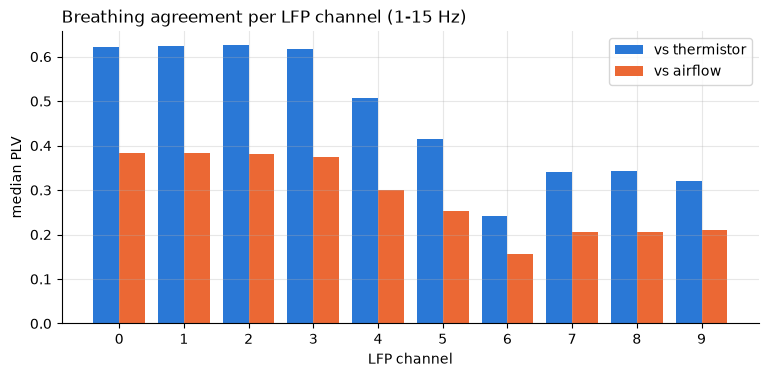

In [27]:
p_th, p_af = phase["Thermistor"], phase["Airflow"]
p_lfp_all = get_phase(lfp_all)                                  # all 10 channels
vs_th = [np.median(sliding_plv(p_lfp_all[:, c], p_th)[1]) for c in range(10)]
vs_af = [np.median(sliding_plv(p_lfp_all[:, c], p_af)[1]) for c in range(10)]

x = np.arange(10)
plt.figure(figsize=(9, 3.8))
plt.bar(x - 0.2, vs_th, 0.4, color=COLORS["Thermistor"], label="vs thermistor")
plt.bar(x + 0.2, vs_af, 0.4, color=COLORS["Airflow"], label="vs airflow")
plt.xticks(x); plt.xlabel("LFP channel"); plt.ylabel("median PLV"); plt.legend()
plt.title("Breathing agreement per LFP channel (1-15 Hz)", loc="left"); plt.show()

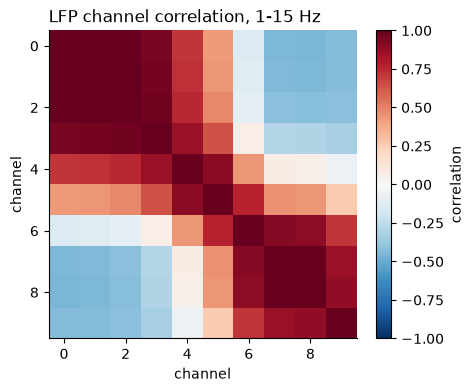

channel 0 vs: 0: 1.00  1: 1.00  2: 1.00  3: 0.95  4: 0.71  5: 0.43  6: -0.13  7: -0.45  8: -0.46  9: -0.44


In [28]:
lfp_breath = bandpass(lfp_all, 1, 15)
corr_breath = np.corrcoef(lfp_breath.T)

plt.figure(figsize=(5, 4))
plt.imshow(corr_breath, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="correlation"); plt.xlabel("channel"); plt.ylabel("channel"); plt.grid(False)
plt.title("LFP channel correlation, 1-15 Hz", loc="left"); plt.show()
print("channel 0 vs:", "  ".join(f"{c}: {v:.2f}" for c, v in enumerate(corr_breath[0])))

**Result:** channels 0–3 are tied for best agreement; channel 0 is used throughout. In the breathing band, channels 7–9 are negatively correlated with channels 0–3 (about −0.45): the breathing signal appears to reverse sign along the probe, with the weakest breathing signal near channel 6 where it crosses over.

## 10. Filter band
Median agreement for each sensor pair as the band-pass filter narrows.

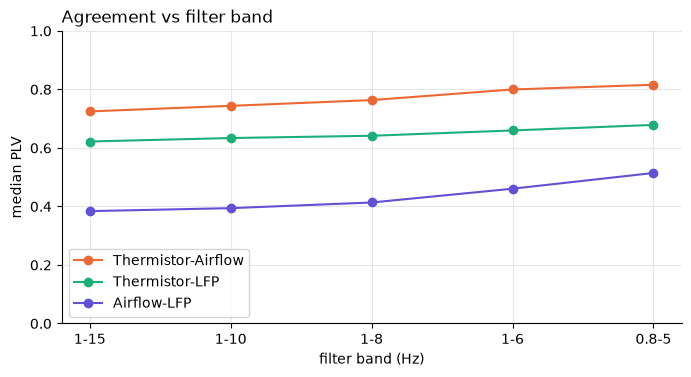

Thermistor-Airflow     1-15: 0.72  1-10: 0.74  1-8: 0.76  1-6: 0.80  0.8-5: 0.82
Thermistor-LFP         1-15: 0.62  1-10: 0.63  1-8: 0.64  1-6: 0.66  0.8-5: 0.68
Airflow-LFP            1-15: 0.38  1-10: 0.39  1-8: 0.41  1-6: 0.46  0.8-5: 0.51


In [29]:
bands = [(1, 15), (1, 10), (1, 8), (1, 6), (0.8, 5)]
table = {f"{a}-{b}": [] for a, b in pairs}
for lo, hi in bands:
    ph_b = {name: get_phase(x, lo, hi) for name, x in sensors.items()}
    for a, b in pairs:
        table[f"{a}-{b}"].append(np.median(sliding_plv(ph_b[a], ph_b[b])[1]))

labels = [f"{lo}-{hi}" for lo, hi in bands]
plt.figure(figsize=(8, 3.8))
for (name, vals), c in zip(table.items(), pair_colors):
    plt.plot(labels, vals, "o-", color=c, label=name)
plt.xlabel("filter band (Hz)"); plt.ylabel("median PLV"); plt.ylim(0, 1); plt.legend()
plt.title("Agreement vs filter band", loc="left"); plt.show()
for name, vals in table.items():
    print(f"{name:22s}", "  ".join(f"{l}: {v:.2f}" for l, v in zip(labels, vals)))

**Result:** agreement rises for every pair as the band narrows. Much of the 5–15 Hz content is not shared between sensors. But a narrower band would also remove genuine fast breathing (sniffing, ~6–12 Hz), so higher agreement alone doesn't make it the right choice.

**Next steps:**
1. Baseline: reconstruct each sensor from the other two with a lag-corrected circular average.
2. Corruption functions (frozen phase, noise, extra cycles) and how much corruption the baseline tolerates.
3. First network, compared against the baseline.